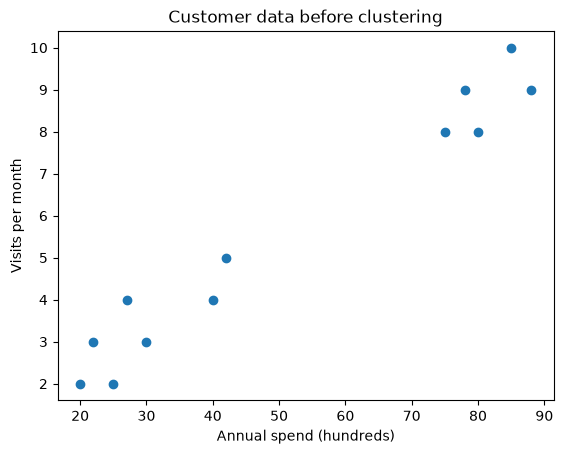

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


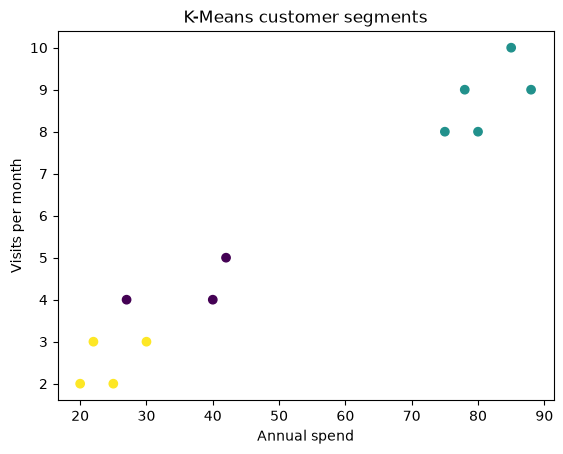

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0
5 inertia: 0.38 silhouette: 0.4
Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


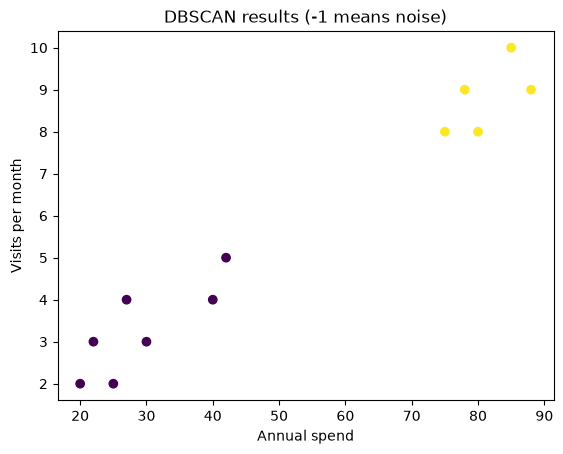

Explained variance: [0.73  0.229]


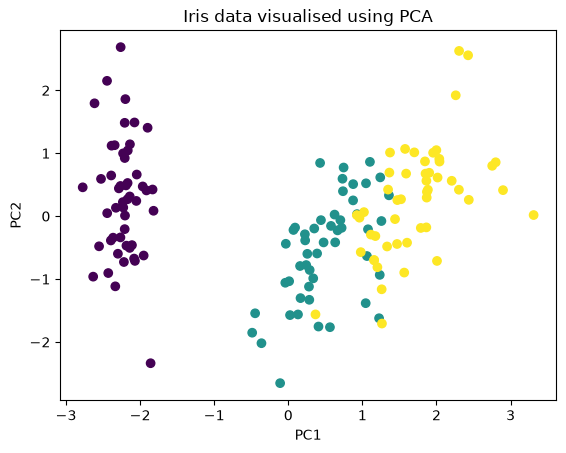

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


In [7]:
import pandas as pd

import matplotlib.pyplot as plt

customers = pd.DataFrame({

"AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],

"VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]

})

plt.scatter(customers["AnnualSpend"],

customers["VisitsPerMonth"])

plt.xlabel("Annual spend (hundreds)")

plt.ylabel("Visits per month")

plt.title("Customer data before clustering")

plt.show()
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

scaler = StandardScaler()

X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)

customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],

customers["VisitsPerMonth"],

c=customers["Cluster"])

plt.xlabel("Annual spend")

plt.ylabel("Visits per month")

plt.title("K-Means customer segments")
plt.show()
print(customers)
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score

for k in range(2, 6):

 model = KMeans(n_clusters=k, random_state=42, n_init=10)

labels = model.fit_predict(X_scaled)

print(k,

"inertia:", round(model.inertia_, 2),

"silhouette:", round(silhouette_score(X_scaled, labels), 3))
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)

db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)

print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],

customers["VisitsPerMonth"],

c=db_labels)

plt.xlabel("Annual spend")

plt.ylabel("Visits per month")

plt.title("DBSCAN results (-1 means noise)")
plt.show()
from sklearn.datasets import load_iris

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

iris = load_iris()

X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)

X_2d = pca.fit_transform(X_iris)

print("Explained variance:",

pca.explained_variance_ratio_.round(3))

plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)

plt.xlabel("PC1"); plt.ylabel("PC2")

plt.title("Iris data visualised using PCA")
plt.show()
from sklearn.ensemble import IsolationForest

import numpy as np

transactions = np.array([

[20, 2], [22, 3], [18, 2], [25, 3],

[21, 2], [23, 4], [19, 3], [250, 20]

])

detector = IsolationForest(contamination=0.12, random_state=42)

labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):

 print(row, "Anomaly" if label == -1 else "Normal")


   Annual Spending  Visits per Month
0            20795                12
1             5860                 8
2            81820                24
3            59886                11
4            11265                19
[[-1.24695732 -0.24898397]
 [-1.77498241 -0.69559198]
 [ 0.91057405  1.09084008]
 [ 0.13510018 -0.36063597]
 [-1.5838893   0.53258006]]
   Annual Spending  Visits per Month  Cluster
0            20795                12        0
1             5860                 8        0
2            81820                24        2
3            59886                11        1
4            11265                19        0


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


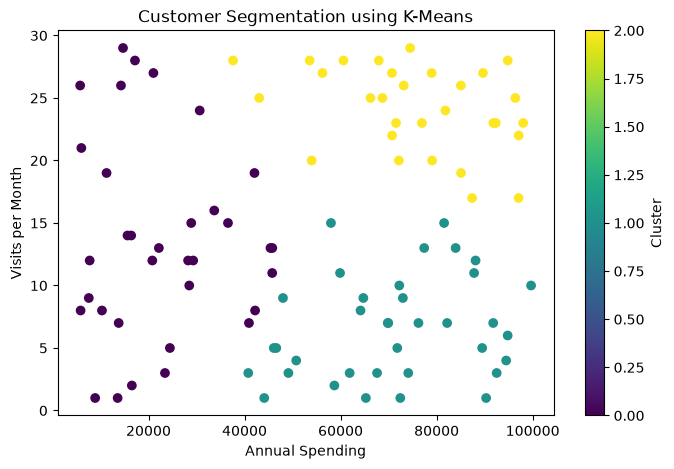

Cluster
0    22802.647059
1    71087.222222
2    75734.800000
Name: Annual Spending, dtype: float64
K = 2
Inertia = 116.97846266529777
Silhouette Score = 0.40296233956896477
---------------------
K = 3
Inertia = 65.1317405089007
Silhouette Score = 0.4448467364790244
---------------------
K = 4
Inertia = 42.69298323693813
Silhouette Score = 0.45998143877323566
---------------------


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

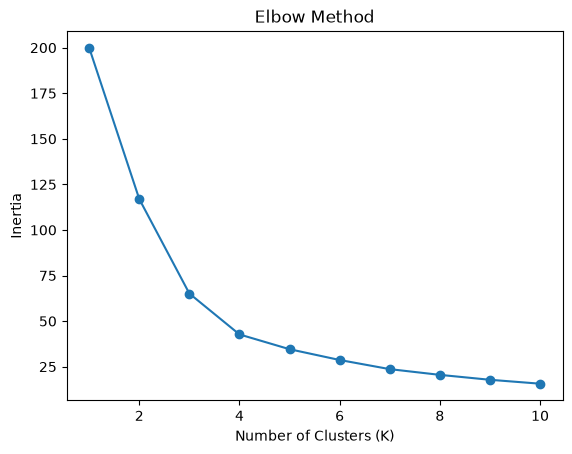

DBSCAN_Cluster
 0    85
 1     6
-1     5
 2     4
Name: count, dtype: int64


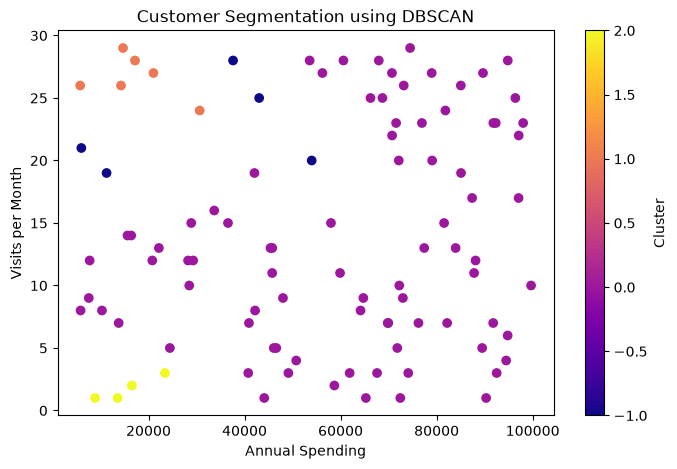

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Create sample customer dataset
np.random.seed(42)

df = pd.DataFrame({
    'Annual Spending': np.random.randint(5000, 100000, 100),
    'Visits per Month': np.random.randint(1, 30, 100)
})

print(df.head())
X = df[['Annual Spending', 'Visits per Month']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df.head())
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual Spending'],
    df['Visits per Month'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits per Month')
plt.title('Customer Segmentation using K-Means')
plt.colorbar(label='Cluster')
plt.show()
average_spending = df.groupby('Cluster')['Annual Spending'].mean()

print(average_spending)
for k in [2, 3, 4]:

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print("K =", k)
    print("Inertia =", model.inertia_)
    print("Silhouette Score =", score)
    print("---------------------")
    inertia_values = []

for k in range(1, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

plt.plot(range(1, 11), inertia_values, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()
dbscan = DBSCAN(eps=0.5, min_samples=5)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print(df['DBSCAN_Cluster'].value_counts())
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual Spending'],
    df['Visits per Month'],
    c=df['DBSCAN_Cluster'],
    cmap='plasma'
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits per Month')
plt.title('Customer Segmentation using DBSCAN')
plt.colorbar(label='Cluster')
plt.show()